# Which song fits this playlist?
Five example songs, two candidates, one observed member. Can a model recognize the missing song from its sound, or does it need evidence about which artists people put together?

**Main finding.** Across 1,000 choices on 100 held-out playlists, an audio-and-artist classifier selected 74.7% of the recorded members. Adding artist co-occurrence raised accuracy to 86.2%. On a harder test where both candidates share an artist, the extended model scored 53.5%. The identity of the alternative changes what this task measures.

**Reading the experiment.** Section 1 defines the choice, Section 2 examines the data, Section 3 compares course models, Section 4 tests them on held-out playlists, and Section 5 interprets the result alongside published work.

**Study origin.** The linked student project introduced this exact two-candidate task and reported 74.7% accuracy for logistic regression. This notebook independently implements its split, random queries and audio/artist benchmark. The additional classifiers, artist co-occurrence experiment and same-artist test extend that study. [Reference notebook](https://github.com/tjp095/Spotify_Song_Recommender/blob/main/assignment_2.ipynb)

## 1 · Predictive task
Given five distinct tracks sampled from one playlist, choose between two other tracks. One is a hidden member. The other is drawn uniformly from recordings absent from the entire playlist. Either candidate can occupy the left slot. Positions and play order play no role.

**Unit of evaluation.** Each eligible playlist contributes ten choices. Accuracy counts a correct choice as 1 and a tied score as ½, the expected credit for a fair coin. Random guessing earns 50%. Each error costs the same and exactly one candidate is relevant, so two-choice accuracy directly answers the question. Full-catalog recall, skips and listener satisfaction would require different experiments.

**Decision rule.** Select the model and tuning parameters on validation accuracy using uniform alternatives. Keep those choices fixed on test. Compare every method on identical candidate pairs, including a harder follow-up that holds the candidate artist constant. A playlist-level paired interval measures how consistently a gain occurs across playlists.

**Reproduce.** Place the original CSV beside this notebook or in a local `data` folder, or set `SONGS620_PATH`. The code also recognizes a Desktop copy. Run cells in order. The HTML embeds the figures and tables.

In [1]:
from pathlib import Path
import hashlib, os, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.sparse import csr_matrix
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import CategoricalNB
from IPython.display import display, Markdown
%matplotlib inline
plt.rcParams.update({'figure.dpi': 112, 'axes.spines.top': False, 'axes.spines.right': False})
teal, blue, gold = '#14776e', '#36597e', '#b36c27'
pd.options.display.float_format = '{:,.3f}'.format
paths = [Path('songs620.csv'), Path('data/songs620.csv'), Path.home()/'Desktop'/'songs620.csv']
if 'SONGS620_PATH' in os.environ:
    paths = [Path(os.environ['SONGS620_PATH']).expanduser()]
path = next((p for p in paths if p.is_file()), None)
if path is None:
    raise FileNotFoundError('Place songs620.csv beside this notebook, or set SONGS620_PATH.')
digest = hashlib.sha256(path.read_bytes()).hexdigest()
assert digest == '11533e4997668e7791c093bbcc63fb20ed820e8c4bbd80b7026fedaf1fb8d946'
print('Input SHA-256', digest)
print('Python', platform.python_version(), '| NumPy', np.__version__, '| pandas', pd.__version__,
      '| SciPy', scipy.__version__, '| scikit-learn', sklearn.__version__)

Input SHA-256 11533e4997668e7791c093bbcc63fb20ed820e8c4bbd80b7026fedaf1fb8d946
Python 3.14.0 | NumPy 2.4.1 | pandas 3.0.0 | SciPy 1.17.0 | scikit-learn 1.8.0


## 2 · Data collection, preparation and exploration
The file is a byte-for-byte match to the published AC209A Group 137 slice. The group describes enriching Million Playlist Dataset tracks with Spotify audio features. Spotify collected public, user-created US playlists from 2010–2017. This single slice has no individual listener judgments, curator IDs or creation dates for a chronological evaluation. [Upstream Spotify collection](https://engineering.atspotify.com/2018/05/introducing-the-million-playlist-dataset-and-recsys-challenge-2018) · [Enrichment project](https://suton5.github.io/recsys137/) · [Published CSV](https://github.com/suton5/recsys137/blob/master/test_data/songs620.csv)

A recording URI identifies a track across playlists. Collapse repeated occurrences within each playlist because the label is membership. Split playlist IDs first. Static artist and audio metadata are available across the snapshot. Fit scaling and estimate interaction history from training playlists. A track shared across splits is legitimate in this known-catalog experiment.

In [2]:
audio_cols = ['danceability','energy','loudness','speechiness','acousticness',
              'instrumentalness','liveness','valence','tempo','duration_ms']
df = pd.read_csv(path)
required = ['pid','track_uri','artist_uri',*audio_cols]
assert df[required].notna().all().all() and np.isfinite(df[audio_cols]).all().all()
assert df.groupby('track_uri')[['artist_uri',*audio_cols]].nunique().le(1).all().all()
catalog = df.drop_duplicates('track_uri').set_index('track_uri').sort_index()
df['item'] = catalog.index.get_indexer(df.track_uri)
members = {p: np.unique(g.item) for p,g in df.groupby('pid')}
artist = pd.factorize(catalog.artist_uri)[0]
items = np.arange(len(catalog))
ids = np.random.default_rng(42).permutation(sorted(members))
train, valid, test = ids[:800], ids[800:900], ids[900:]
assert len(ids)==1000 and len(set(train)|set(valid)|set(test))==sum(map(len,[train,valid,test]))
train_counts = np.bincount(np.concatenate([members[p] for p in train]), minlength=len(items))
audio = catalog[audio_cols].to_numpy().copy()
audio[:,-2:] = np.log1p(audio[:,-2:])  # Same tempo/duration transformation as the reference.
z = StandardScaler().fit(audio[train_counts>0]).transform(audio)
split_rows = []
for label, group in [('Train',train),('Validation',valid),('Test',test)]:
    eligible = sum(len(members[p])>=6 for p in group)
    split_rows.append([label,len(group),eligible,eligible*10])
display(pd.DataFrame(split_rows,columns=['Split','Playlists','Eligible','Queries']).set_index('Split'))
print(f'{len(df):,} placements · {len(catalog):,} recordings · {len(set(artist)):,} artists · '
      f'{df.duplicated(["pid","item"]).sum():,} repeated memberships collapsed')

,Playlists,Eligible,Queries
Split,,,
Train,800,795,7950
Validation,100,98,980
Test,100,100,1000


66,263 placements · 36,203 recordings · 9,963 artists · 854 repeated memberships collapsed


In [3]:
context_cols = [f'seed{i}' for i in range(1,6)]
def sample_queries(group, seed):
    rng = np.random.default_rng(seed)
    records = []
    for pid in sorted(group):
        songs = members[pid]
        if len(songs)<6:
            continue
        outside = np.setdiff1d(items,songs,assume_unique=True)
        for j in range(10):
            six = rng.choice(songs,6,replace=False)
            other = rng.choice(outside)
            side = int(rng.integers(2))
            a,b = (six[-1],other) if side else (other,six[-1])
            records.append([pid,j,*six[:5],a,b,side])
    return pd.DataFrame(records,columns=['pid','query',*context_cols,'a','b','y'])

training = sample_queries(train,43)
validation = sample_queries(valid,44)
def check_queries(q):
    for pid,g in q.groupby('pid'):
        context = g[context_cols].to_numpy()
        pos = np.where(g.y,g.a,g.b)
        neg = np.where(g.y,g.b,g.a)
        assert (np.diff(np.sort(context),axis=1)>0).all() and (pos[:,None]!=context).all()
        assert np.isin(context,members[pid]).all() and np.isin(pos,members[pid]).all()
        assert not np.isin(neg,members[pid]).any()
check_queries(training)
check_queries(validation)

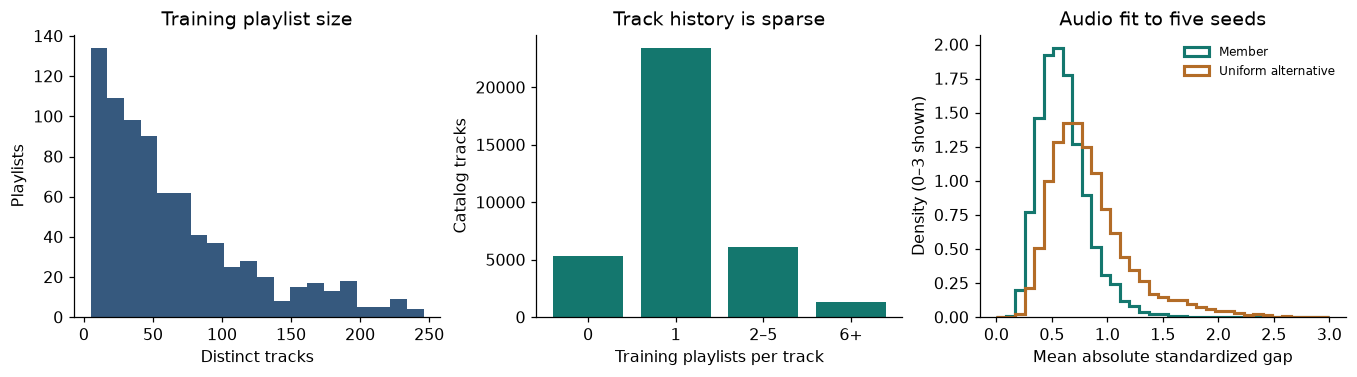

28,779 catalog songs have history in at most one training playlist.
Artist appears among seeds: 17.0% for members, 0.2% for alternatives.
Median audio gap: member 0.58, alternative 0.77.


In [4]:
q = training
seeds = q[context_cols].to_numpy()
pos, neg = np.where(q.y,q.a,q.b), np.where(q.y,q.b,q.a)
fig, ax = plt.subplots(1,3,figsize=(12,3.25),layout='constrained')
ax[0].hist([len(members[p]) for p in train],bins=20,color=blue)
ax[0].set(title='Training playlist size',xlabel='Distinct tracks',ylabel='Playlists')
counts = [sum(train_counts==0),sum(train_counts==1),sum((train_counts>=2)&(train_counts<=5)),sum(train_counts>=6)]
ax[1].bar(['0','1','2–5','6+'],counts,color=teal)
ax[1].set(title='Track history is sparse',xlabel='Training playlists per track',ylabel='Catalog tracks')
center = z[seeds].mean(axis=1)
bins = np.linspace(0,3,36)
for candidates,label,col in [(pos,'Member',teal),(neg,'Uniform alternative',gold)]:
    distance = np.abs(z[candidates]-center).mean(axis=1)
    ax[2].hist(distance,bins=bins,density=True,histtype='step',lw=2,color=col,label=label)
ax[2].legend(frameon=False,fontsize=8)
ax[2].set(title='Audio fit to five seeds',xlabel='Mean absolute standardized gap',ylabel='Density (0–3 shown)')
plt.show()
def artist_overlap(candidates):
    return (artist[candidates,None]==artist[seeds]).any(axis=1).mean()
print(f'{sum(train_counts<=1):,} catalog songs have history in at most one training playlist.')
print(f'Artist appears among seeds: {artist_overlap(pos):.1%} for members, {artist_overlap(neg):.1%} for alternatives.')
print(f'Median audio gap: member {np.median(abs(z[pos]-center).mean(1)):.2f}, alternative {np.median(abs(z[neg]-center).mean(1)):.2f}.')

The first panel shows why each playlist gets ten queries. Sampling every possible group would give long playlists much greater influence. The second motivates pooling history at artist level. The overlapping audio distributions in the third explain both the value and the limits of a distance-only rule. A random outsider can differ on sound and artist at the same time. The harder test in Section 4 removes one of these shortcuts.

## 3 · Modeling and selection
For each candidate, measure closeness to the five example songs. Subtract B’s feature vector from A’s. Positive values favor A. Mirroring every training pair with its reversed label removes candidate-side bias. A valid choice reverses when the two candidates trade places.

| Method | What it learns or measures | Why compare it here? |
|---|---|---|
| Chance, popularity, artist overlap | A fair coin, training playlist count, or fraction of seeds by the candidate artist | Establish guessing, broad appeal and same-performer shortcuts |
| Audio distance | Sum of ten negative absolute distances to the seed centroid | Simple content-based recommendation with no fitted preference weights |
| Artist cosine | Mean cosine similarity of candidate and seed artists’ binary training-playlist vectors | Collaborative filtering can connect different artists curated together. Unseen artists contribute zero |
| Logistic regression | L2-penalized binary log loss on feature differences | An interpretable weighted combination; audio-only and audio + artist fits reproduce the reference comparison |
| Linear SVM | L2-penalized squared hinge loss on the same twelve audio + artist inputs | Tests whether a margin objective helps with the same evidence |
| Categorical naïve Bayes | Smoothed class-conditional counts for whether each feature favors A, ties or favors B | Tests a generative model. Discretization loses magnitude, and correlated audio dimensions challenge conditional independence |
| Hybrid logistic regression | Adds a thirteenth feature, artist cosine, to the twelve-feature logistic model | Direct test of whether co-curation adds information beyond sound and shared identity |

The twelve features are ten per-descriptor closeness values, closest-seed audio distance, and artist overlap. The collaborative lookup is sparse and requires building a history index. After feature extraction, all learned models score a pair in time proportional to the feature count. Logistic regression and SVM require iterative fitting. Naïve Bayes estimates counts in one pass. Signed differences make a multinomial word-count likelihood inappropriate here. [Classification lectures](https://drive.google.com/file/d/1fUrZCpQ6Sx92blcn6NshOPEWxb27Jp6k/view) · [Recommendation lectures](https://drive.google.com/file/d/1VAt1C5Za5JCBXUkeRbqkH8jajgTdfmnl/view)

In [5]:
def artist_index(group):
    rows, cols = [], []
    for j,pid in enumerate(group):
        artists = np.unique(artist[members[pid]])
        rows.extend(artists)
        cols.extend([j]*len(artists))
    matrix = csr_matrix((np.ones(len(rows)),(rows,cols)),shape=(artist.max()+1,len(group)))
    norms = np.sqrt(np.asarray(matrix.sum(axis=1)).ravel()).clip(1)
    return matrix.multiply((1/norms)[:,None]).tocsr()

def features(q, history):
    seeds = q[context_cols].to_numpy()
    audio_seeds = z[seeds]
    center = audio_seeds.mean(axis=1)
    seed_artists = artist[seeds]
    def candidate(idx):
        gap = -abs(z[idx]-center)
        nearest = -np.linalg.norm(audio_seeds-z[idx,None,:],axis=2).min(axis=1)
        ids = artist[idx]
        match = (ids[:,None]==seed_artists).mean(axis=1)
        vectors = history[ids]
        cosine = np.column_stack([
            np.asarray(vectors.multiply(history[col]).sum(axis=1)).ravel()
            for col in seed_artists.T
        ]).mean(axis=1)
        return np.column_stack([gap,nearest,match,cosine])
    return candidate(q.a.to_numpy()) - candidate(q.b.to_numpy())

# A training playlist must never contribute to its own artist co-occurrence features.
X_train = np.empty((len(training),13))
for keep, hold in KFold(4,shuffle=True,random_state=75).split(train):
    mask = training.pid.isin(train[hold])
    assert set(training.loc[mask,'pid']).isdisjoint(train[keep])
    X_train[mask] = features(training.loc[mask], artist_index(train[keep]))
history = artist_index(train)
X_val = features(validation,history)
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()

**Selection protocol.** Fit on the mirrored training queries. Tune each regularization or smoothing parameter on the 98 eligible validation playlists. Within a model choose the smallest parameter achieving the best accuracy. Across models choose the highest validation accuracy, resolving exact ties in the order listed in the code. Every variant faces the same validation pairs. Keep the original training fits for testing. The uniform-negative benchmark and its original test result were public before this extension, so replication on a second slice would provide an independent confirmation.

In [6]:
# Listed order gives simpler fixed rules priority in an exact validation tie.
rules = ['Chance','Popularity','Artist overlap','Audio distance','Artist cosine']
specs = {'Logistic · audio':('logistic',11), 'Logistic · audio + artist':('logistic',12),
         'Linear SVM':('svm',12),'Naïve Bayes':('bayes',12),'Hybrid logistic':('logistic',13)}
def rule_scores(q,x):
    return dict(zip(rules,[np.zeros(len(q)),train_counts[q.a]-train_counts[q.b],
                           x[:,11],x[:,:10].sum(axis=1),x[:,12]]))

def score_model(model,kind,x):
    if kind=='bayes':
        # Three sign categories 0, 1, 2 correspond to B, tie, A.
        logp = model.predict_log_proba(np.sign(x).astype(int)+1)
        return logp[:,1]-logp[:,0]
    return model.decision_function(x)

def credit(scores,y):
    signed = scores*(2*np.asarray(y)-1)
    return np.where(np.isclose(signed,0,atol=1e-10,rtol=0),.5,signed>0)

def fit_model(kind,x,y,param):
    x = np.vstack([x,-x])
    y = np.r_[y,1-y]
    if kind=='bayes':
        return CategoricalNB(alpha=param,min_categories=3).fit(np.sign(x).astype(int)+1,y)
    est = (LinearSVC(C=param,fit_intercept=False,dual=False,max_iter=10000) if kind=='svm'
           else LogisticRegression(C=param,fit_intercept=False,max_iter=2000))
    return make_pipeline(StandardScaler(with_mean=False),est).fit(x,y)

validation_scores = rule_scores(validation,X_val)
fitted, grid = {}, []
for name,(kind,n) in specs.items():
    options = []
    for p in ([.1,1.,10.] if kind=='bayes' else [.01,.1,1.,10.]):
        model = fit_model(kind,X_train[:,:n],training.y.to_numpy(),p)
        scores = score_model(model,kind,X_val[:,:n])
        acc = credit(scores,validation.y).mean()
        grid.append([name,p,acc])
        options.append((acc,-p,model,scores))
    acc,neg_p,model,scores = max(options,key=lambda row:row[:2])
    fitted[name] = model
    validation_scores[name] = scores
val_acc = {k:credit(v,validation.y).mean() for k,v in validation_scores.items()}
winner = max(val_acc,key=val_acc.get)
display(pd.DataFrame(grid,columns=['Model','C or smoothing α','Accuracy'])
        .pivot(index='Model',columns='C or smoothing α',values='Accuracy').style.format('{:.1%}',na_rep='—'))
print(f'Frozen primary model: {winner} ({val_acc[winner]:.1%} validation accuracy)')

C or smoothing α,0.010000,0.100000,1.000000,10.000000
Model,,,,
Hybrid logistic,87.7%,87.9%,88.0%,88.0%
Linear SVM,77.8%,77.9%,77.8%,77.8%
Logistic · audio,74.6%,74.4%,74.5%,74.5%
Logistic · audio + artist,78.0%,77.9%,77.9%,77.9%
Naïve Bayes,—,76.2%,76.2%,76.2%


Frozen primary model: Hybrid logistic (88.0% validation accuracy)


## 4 · Evaluation on held-out playlists
There are ten queries per eligible playlist on the primary task. Average credits within each playlist, then average those means. Resample whole playlists 10,000 times for percentile intervals. For model comparisons, resample the within-playlist difference so that the two methods always face identical choices. These intervals describe the fixed fitted models and sampled alternatives. They omit uncertainty from retraining, shared curators and trying another dataset.

,Validation,Test,Lower 95%,Upper 95%,Ties
Chance,50.0%,50.0%,50.0%,50.0%,100.0%
Popularity,51.3%,54.4%,49.0%,59.8%,16.0%
Artist overlap,58.3%,58.5%,56.4%,61.0%,82.7%
Audio distance,73.7%,68.8%,65.3%,72.4%,0.0%
Artist cosine,78.4%,81.4%,78.4%,84.4%,18.6%
Logistic · audio,74.6%,69.9%,66.8%,73.0%,0.0%
Logistic · audio + artist,78.0%,74.7%,71.5%,77.8%,0.0%
Linear SVM,77.9%,74.6%,71.4%,77.7%,0.0%
Naïve Bayes,76.2%,71.5%,68.0%,75.0%,0.0%
Hybrid logistic,88.0%,86.2%,83.4%,88.9%,0.0%


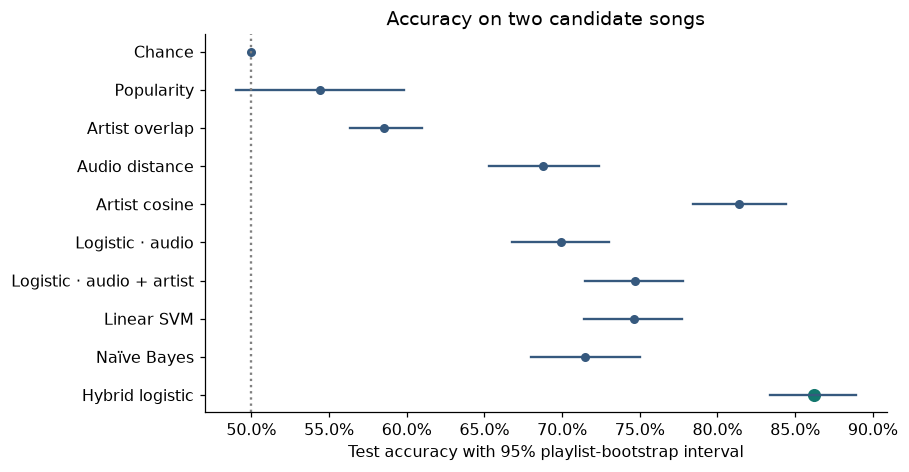

,Gain (pp),Lower 95% (pp),Upper 95% (pp)
Hybrid logistic minus Audio distance,17.400,14.100,20.700
Hybrid logistic minus Logistic · audio + artist,11.500,8.600,14.500
Hybrid logistic minus Artist cosine,4.800,2.250,7.500
Linear SVM minus Logistic · audio + artist,-0.100,-0.400,0.200
Naïve Bayes minus Logistic · audio + artist,-3.200,-5.300,-1.100


In [7]:
testing = sample_queries(test,45)
check_queries(testing)
def evaluate(q):
    x = features(q,history)
    scores = rule_scores(q,x)
    for name,(kind,n) in specs.items():
        scores[name] = score_model(fitted[name],kind,x[:,:n])
        rev = score_model(fitted[name],kind,-x[:,:n])
        np.testing.assert_allclose(scores[name],-rev,atol=1e-9,rtol=1e-9)
    credits = pd.DataFrame({k:credit(v,q.y) for k,v in scores.items()},index=q.index)
    return scores,credits

def interval(values):
    v = np.asarray(values,float)
    rng = np.random.default_rng(2026)
    means = v[rng.integers(len(v),size=(10000,len(v)))].mean(axis=1)
    return np.quantile(means,[.025,.975])

scores, points = evaluate(testing)
per_list = points.groupby(testing.pid).mean()
table = pd.DataFrame({'Validation':val_acc,'Test':per_list.mean(),
                      'Lower 95%':per_list.apply(lambda s:interval(s)[0]),
                      'Upper 95%':per_list.apply(lambda s:interval(s)[1]),
                      'Ties':{k:np.isclose(v,0,atol=1e-10).mean() for k,v in scores.items()}})
display(table.style.format('{:.1%}'))
fig,ax=plt.subplots(figsize=(8,4.1),layout='constrained')
for i,(name,r) in enumerate(table.iterrows()):
    ax.plot([r['Lower 95%'],r['Upper 95%']],[i,i],color=blue)
    ax.scatter(r.Test,i,color=teal if name==winner else blue,s=55 if name==winner else 23)
ax.set_yticks(np.arange(len(table)),table.index)
ax.invert_yaxis()
ax.axvline(.5,color='gray',ls=':')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(title='Accuracy on two candidate songs',xlabel='Test accuracy with 95% playlist-bootstrap interval')
plt.show()
def difference(a,b):
    diff = a-b
    lo,hi = interval(diff)
    return [diff.mean()*100,lo*100,hi*100]
comparisons = [(winner,'Audio distance'),('Hybrid logistic','Logistic · audio + artist'),
               ('Hybrid logistic','Artist cosine'),('Linear SVM','Logistic · audio + artist'),('Naïve Bayes','Logistic · audio + artist')]
pairs = {f'{a} minus {b}':difference(per_list[a],per_list[b]) for a,b in comparisons}
display(pd.DataFrame.from_dict(pairs,orient='index',columns=['Gain (pp)','Lower 95% (pp)','Upper 95% (pp)']).round(2))

### When both candidates are by the same artist
A uniformly drawn alternative can be easy to rule out by artist identity. Retain the five seeds, positive track and candidate side. Replace the outsider with a randomly chosen recording by the **hidden member’s artist** that is absent from the entire playlist. If none exists, discard that query from **both** conditions. This isolates the change in the alternative on an identical eligible subset. It also restricts the kinds of artists represented. The positive artist is used to construct this diagnostic and is never supplied as the answer to a classifier.

In [8]:
def matched_outsiders(q):
    rng = np.random.default_rng(203)
    by_artist = pd.Series(items).groupby(artist).indices
    keep, alternatives = [], []
    for i,row in q.iterrows():
        target = int(row.a if row.y else row.b)
        pool = np.setdiff1d(by_artist[artist[target]],members[row.pid],assume_unique=True)
        if len(pool):
            keep.append(i)
            alternatives.append(rng.choice(pool))
    hard = q.loc[keep].copy()
    for col,mask in [('a',hard.y.eq(0)),('b',hard.y.eq(1))]:
        hard.loc[mask,col] = np.asarray(alternatives)[mask.to_numpy()]
    return hard

hard = matched_outsiders(testing)
check_queries(hard)
assert (artist[hard.a]==artist[hard.b]).all()
hard_scores, hard_points = evaluate(hard)
assert (hard_points[['Artist overlap','Artist cosine']]==.5).all().all()
matched_uni = points.loc[hard.index].groupby(hard.pid).mean()
matched_hard = hard_points.groupby(hard.pid).mean()
summary = pd.DataFrame({'Uniform outsider':matched_uni.mean(),'Same-artist outsider':matched_hard.mean()})
summary['Change (pp)'] = (summary.iloc[:,1]-summary.iloc[:,0])*100
print(f'Matched sample: {len(hard)} of {len(testing)} choices, {hard.pid.nunique()} playlists.')
display(summary.style.format({'Uniform outsider':'{:.1%}','Same-artist outsider':'{:.1%}','Change (pp)':'{:+.1f}'}))
print('Same-artist primary accuracy, 95% interval (%):', np.round(100*interval(matched_hard[winner]),2))
print('Primary model, same-artist minus uniform (pp):', np.round(difference(matched_hard[winner],matched_uni[winner]),2))

Matched sample: 824 of 1000 choices, 100 playlists.


,Uniform outsider,Same-artist outsider,Change (pp)
Chance,50.0%,50.0%,+0.0
Popularity,59.1%,56.6%,-2.5
Artist overlap,57.7%,50.0%,-7.7
Audio distance,70.6%,56.0%,-14.5
Artist cosine,87.7%,50.0%,-37.7
Logistic · audio,71.2%,53.7%,-17.5
Logistic · audio + artist,75.5%,53.8%,-21.6
Linear SVM,75.5%,53.9%,-21.6
Naïve Bayes,73.1%,53.8%,-19.3
Hybrid logistic,89.1%,53.5%,-35.6


Same-artist primary accuracy, 95% interval (%): [49.38 57.68]
Primary model, same-artist minus uniform (pp): [-35.62 -40.52 -30.82]


### Read one mistake
Select the first incorrect same-artist choice in playlist and query order. This example shows a failure mode. The table above measures its broader context. Both choices could sound plausible to a listener.

In [9]:
wrong = hard_points[winner].eq(0)
idx = hard.index[wrong][0] if wrong.any() else hard.index[0]
case = hard.loc[idx]
names = catalog.reset_index()
def name(i):
    song = names.iloc[int(i)]
    return f'{song.track_name} — {song.artist_name}'
for j,c in enumerate(context_cols,1):
    print(f'{j}. {name(case[c])}')
for side in ['a','b']:
    print(f'Candidate {side.upper()}  {name(case[side])}')
margin = pd.Series(hard_scores[winner],index=hard.index).loc[idx]
print('Model choice:', 'A' if margin>0 else 'B' if margin<0 else 'Tie',
      '| Recorded member:', 'A' if case.y else 'B')
print('Playlist',int(case.pid),'· query',int(case["query"]))

1. Keeping Your Head Up - Jonas Blue Remix [Radio Edit] — Birdy
2. Watch Out — 2 Chainz
3. All We Know — Brevner
4. I Wanna Know — Alesso
5. SummerThing! — Afrojack
Candidate A  Gangsta — Kat Dahlia
Candidate B  Mirror — Kat Dahlia
Model choice: B | Recorded member: A
Playlist 1 · query 6


In the example, both choices are by Kat Dahlia. Artist overlap and co-occurrence assign them identical scores. Acoustic features break the tie in favor of *Mirror*, while the curator included *Gangsta*. A prediction error tells us which recording was absent from this playlist. The data give us no preference judgment between the songs.

## 5 · Findings, related work and scope

**What improved the model?** Adding artist co-occurrence raised accuracy from 74.7% to 86.2% on the original task, a paired improvement of 11.5 percentage points (95% interval 8.6 to 14.5). A stand-alone artist-cosine rule already achieved 81.4%. Switching the loss from logistic to squared hinge moved accuracy by −0.1 points (interval −0.4 to +0.2). Naïve Bayes scored 71.5%. Its comparison changes both the likelihood and the representation because it keeps only the direction of each difference. The results identify artist co-curation as a useful source of evidence and leave the two linear objectives effectively tied on these playlists.

**What happens when the easy clue disappears?** On the 824 eligible queries, the hybrid fell from 89.1% against uniform alternatives to 53.5% against same-artist alternatives. The paired drop was 35.6 points (95% interval for the drop 30.8 to 40.5). Artist cosine ties on every same-artist query by construction. The simple audio-distance rule reached 56.0% on those choices. For choosing between recordings by one performer, testing features such as album context or track-level co-occurrence on fresh playlists is a more direct follow-up than tuning the classifier again.

**Relation to the literature.** Chen et al. describe the 2018 Spotify challenge, where systems recommend many missing tracks and are evaluated using R-precision, NDCG and clicks. Our result supports using playlist co-occurrence as a source of evidence on this slice. The challenge's catalog-scale ranking and our sampled two-song choice have different denominators, so 86.2% cannot serve as a leaderboard comparison. [Chen et al., RecSys 2018](https://research.atspotify.com/publications/recsys-challenge-2018-automatic-music-playlist-continuation)

Vall et al. trained a song-to-playlist classifier with descriptors derived from audio, tags and listening logs. They found feature-based recommendations especially valuable when song histories were sparse. Here 28,779 recordings appear in at most one training playlist. Pooling at artist level supplies a coarser form of history and improves average accuracy. Our same-artist test exposes its resolution limit. We did not estimate their rare-song recall, so the results speak to a shared modeling problem rather than a replication of their metric. [Vall et al., 2017](https://arxiv.org/abs/1705.08283)

**Where the claim travels.** A playlist-disjoint split protects against the same playlist ID appearing in training and testing. Shared artists, related curators, covers and near-duplicate playlists can still induce dependence. Ten choices per playlist and a playlist bootstrap address repeated queries within each playlist. Dates, curator grouping and independent test slices would be needed to assess temporal drift, creator-level generalization and stability across datasets. The practical use supported here is choosing between two supplied candidates under the stated sampling conditions.